In [3]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from hyperopt import STATUS_OK, Trials, fmin, hp, tpe, space_eval
# from sklearn.neural_network import MLPClassifier
from alternateMLPClassifier import AlternateMLPClassifier
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits

%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '6'
os.environ['OPENBLAS_NUM_THREADS'] = '6'
os.environ['MKL_NUM_THREADS'] = '6'
os.environ['VECLIB_MAXIMUM_THREADS'] = '6'
os.environ['NUMEXPR_NUM_THREADS'] = '6'
os.environ['NUM_WORKERS'] = '6'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

/hlabhome/wg-mjames/.conda/envs/james_home/lib/python3.11/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
split_thres = (0.4, 0.6)
addon='unfiltered'
train, test= generate_train_test_dataset(split_thres, addon, early_train_exit=True, validation_set=False)
#train = resample_isis(train)
#test = resample_isis(test)

Loading Dataset
adding column if necessary
Filtering out lame neurons
Splitting into train/test 500 isi chunks


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [01:18<00:00, 54.85it/s]


Add in some ids
minimizing stuff in the train dataset
Not filtering the dataset/downsampling isis, assuming this is intentional!


In [3]:
start_val,stop_val,bin_size = 0.0015,3,0.01 #in seconds
isi_bins = np.arange(start_val,stop_val,bin_size)
N_BINS = 100
BIN_EDGES = np.logspace(np.log10(0.001), np.log10(60), N_BINS + 1)
def obtain_distribution(unit_isi, log_spaced=True):
    if not log_spaced:
        unit_isi_distrib, _ = np.histogram(unit_isi, isi_bins, density=False)
    else: unit_isi_distrib, _ = np.histogram(unit_isi, BIN_EDGES)
    
    if unit_isi_distrib.sum()!=0: #min max normalization
        unit_isi_distrib = (unit_isi_distrib-np.min(unit_isi_distrib))/(np.max(unit_isi_distrib)-np.min(unit_isi_distrib))
    
    return unit_isi_distrib
    
tqdm.pandas()
train['isi_distrib'] = train[f'isi'].progress_apply(obtain_distribution)
test['isi_distrib'] = test[f'isi'].progress_apply(obtain_distribution)
#val['isi_distrib'] = val['isi'].progress_apply(obtain_distribution)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:25<00:00, 19417.00it/s]


In [4]:
# for arr_name, arr in {"train":train, "test":test, "val":val}.items():
#     with open(f"/media/HlabShare/Toby_work/temp_save/{arr_name}.pkl", "wb") as f:
#         pickle.dump(arr, f)
    

In [5]:
#remove any nan values in the isi_distribs
arrs = [train, test]#, val]
for i in range(2):
    arrs[i]['nan_m'] = arrs[i].isi_distrib.progress_apply(lambda x: np.any(np.isnan(x)))
    arrs[i] = arrs[i][~arrs[i].nan_m]
    arrs[i] = arrs[i].drop(columns='nan_m')
    arrs[i] = arrs[i].reset_index(drop=True)
# train, test, val = arrs
train, test = arrs

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:02<00:00, 219852.57it/s]


In [6]:
len(train), len(test)

(1825773, 502898)

In [ ]:
# arrs = []
# for arr_name in ['train', 'test', 'val']:
#     with open(f"/media/HlabShare/Toby_work/temp_save/{arr_name}.pkl", "rb") as f:
#         arrs.append(pickle.load(f))
# train, test, val = arrs

In [6]:
def extract_space_eval(space, trial):
    unpacked_trial = space_eval(space, {k: v[0] for (k, v) in trial['misc']['vals'].items() if len(v) > 0})
    return unpacked_trial
    
def unpack_dictionary(dictionary):
    unpacked = {}
    for (key, value) in dictionary.items():
        if isinstance(value, dict):
            unpacked = {**unpacked, **unpack_dictionary(value)}
        else:
            unpacked[key] = value
            
    return unpacked

In [7]:
# all_counts = train.state.value_counts() +test.state.value_counts()
# max_class_size = int(0.5*max(all_counts)) #maximum train size
# class_explr_binwidth = 100; #bindiwth from 0 to 2*max_class_size to explore for class im(balance)
# space={'hls': hp.quniform('hls',50,600,50),
#        'learning_rate_init': hp.choice('learning_rate_init',[1E-7,1E-6,1E-5,1E-4,1E-3,1E-2,1E-1]),
#        'bs': hp.quniform('bs',25,500,50),
#        'alpha': hp.choice('alpha',[1E-4,1E-3,1E-2,1E-1,1E0,5,10]),
#        'beta_1': hp.quniform('beta_1',0.5,0.9,0.1),
#       }

# def objective(space):
#     print("Made it here")
#     feature = 'isi_distrib'
    
#     X_train, X_test, X_val = train[feature], test[feature], val[feature]
#     y_train, y_test, y_val = train['state'], test['state'], val['state']
    
#     train_bas  = []
#     val_bas = []
#     print("Made it here?", flush=True)
#     #X_train = np.array(X_train.to_numpy().tolist())
#     #y_train = y_train.to_numpy()
#     X_train = list(X_train)
#     X_train = np.array(X_train)
#     print("Past this", flush=True)
#     y_train = y_train.to_numpy()
#     #smote_instance = SMOTE(random_state=42)
#     #X_train, y_train = smote_instance.fit_resample(X_train,y_train)
#     #print(X_train, y_train, flush=True)
#     #validation set        
#     X_val = np.array(X_val.to_numpy().tolist())
#     y_val = y_val.to_numpy()
    
#     clf = MLPClassifier(hidden_layer_sizes = int(space['hls']),
#                         alpha = space['alpha'],
#                         beta_1 = space['beta_1'],
#                         learning_rate_init = space['learning_rate_init'],
#                         batch_size = int(space['bs']),
#                         max_iter=100,
#                         random_state = 42)
#     #print(type(X_train))
#     print("Right before training!", flush=True)
#     with threadpool_limits(limits=4):
#         clf.fit(X_train, y_train)
#     print("After training")
#     #prediction
#     y_val_pred = clf.predict(X_val)
#     y_train_pred = clf.predict(X_train)

#     #plot the loss curves
# #         plt.rcParams['figure.figsize'] = [3, 3]
# #         plt.plot(range(len(clf.loss_curve_)),clf.loss_curve_)
# #         plt.show()

#     train_bas.append(balanced_accuracy_score(y_train, y_train_pred))
#     val_bas.append(balanced_accuracy_score(y_val, y_val_pred))
        
#     print(dict(Counter(y_train)))
#     print({'hls':space['hls'],
#            'bs':space['bs'],
#            'alpha':space['alpha'],
#            'lr_init':space['learning_rate_init'],
#            'beta_1':space['beta_1']})
#     print({'train_ba':np.mean(train_bas),'val_ba':np.mean(val_bas)})
#     return {'loss': -np.mean(val_bas),'status': STATUS_OK}


# trials = Trials()
# optimization = fmin(fn=objective,space=space,algo=tpe.suggest,max_evals=100,trials=trials)

# history = pd.DataFrame([unpack_dictionary(extract_space_eval(space, x)) for x in trials.trials])
# history['val_accuracy'] = pd.DataFrame(trials.results).loss*-1


In [8]:
models = mlp_by_animal(train)

  0%|                                                                                                                                              | 0/17 [00:00<?, ?it/s]

Looking at  caf69(wt,old) in total
Looking at  caf69_358_1228_0_12_0_wt
Looking at  caf69_358_1228_0_12_1_wt
Looking at  caf69_358_1228_0_12_2_wt
Looking at  caf69_358_1228_0_12_3_wt
Looking at  caf69_358_1228_0_12_4_wt
Looking at  caf69_358_1228_0_12_5_wt
Looking at  caf69_358_1228_0_12_6_wt
Looking at  caf69_358_1228_0_12_7_wt
Looking at  caf69_358_1228_0_12_8_wt
Looking at  caf69_358_1228_0_12_9_wt
Looking at  caf69_358_1228_0_12_10_wt
Looking at  caf69_358_1228_0_12_11_wt
Looking at  caf69_358_1228_0_12_12_wt
Looking at  caf69_358_1228_0_12_13_wt
Looking at  caf69_358_1228_0_12_14_wt
Looking at  caf69_358_1228_0_12_15_wt
Looking at  caf69_358_1228_0_12_16_wt
Looking at  caf69_358_1228_0_12_17_wt
Looking at  caf69_358_1228_0_12_18_wt
Looking at  caf69_358_1228_0_12_19_wt
Looking at  caf69_358_1228_0_12_20_wt
Looking at  caf69_358_1228_0_12_21_wt
Looking at  caf69_358_1228_0_12_22_wt
Looking at  caf69_358_1228_0_12_23_wt
Looking at  caf69_358_1228_0_12_24_wt
Looking at  caf69_358_122

Looking at  caf69_361_1230_12_24_24_wt
Looking at  caf69_361_1230_12_24_25_wt
Looking at  caf69_361_1230_12_24_26_wt
Looking at  caf69_361_1230_12_24_27_wt
Looking at  caf69_361_1230_12_24_28_wt
Looking at  caf69_361_1230_12_24_29_wt
Looking at  caf69_361_1230_12_24_30_wt
Looking at  caf69_361_1230_12_24_31_wt
Looking at  caf69_361_1230_12_24_32_wt
Looking at  caf69_361_1230_12_24_33_wt
Looking at  caf69_361_1230_12_24_34_wt
Looking at  caf69_361_1230_12_24_35_wt
Looking at  caf69_361_1230_12_24_36_wt
Looking at  caf69_361_1230_12_24_37_wt
Looking at  caf69_361_1230_12_24_38_wt
Looking at  caf69_361_1230_12_24_39_wt
Looking at  caf69_361_1230_12_24_40_wt
Looking at  caf69_361_1230_12_24_41_wt
Looking at  caf69_361_1230_12_24_42_wt
Looking at  caf69_361_1230_12_24_43_wt
Looking at  caf69_361_1230_12_24_44_wt
Looking at  caf69_361_1230_12_24_45_wt
Looking at  caf69_361_1230_12_24_46_wt
Looking at  caf69_361_1230_12_24_47_wt
Looking at  caf69_361_1230_12_24_48_wt
Looking at  caf69_361_123

  6%|███████▋                                                                                                                           | 1/17 [09:57<2:39:21, 597.59s/it]

Looking at  caf71(app_ps1,old) in total
Looking at  caf71_492_0103_0_12_0_app_ps1
Looking at  caf71_492_0103_0_12_1_app_ps1
Looking at  caf71_492_0103_0_12_2_app_ps1
Looking at  caf71_492_0103_0_12_3_app_ps1
Looking at  caf71_492_0103_0_12_4_app_ps1
Looking at  caf71_492_0103_0_12_5_app_ps1
Looking at  caf71_492_0103_0_12_6_app_ps1
Looking at  caf71_492_0103_0_12_7_app_ps1
Looking at  caf71_492_0103_0_12_8_app_ps1
Looking at  caf71_492_0103_0_12_9_app_ps1
Looking at  caf71_492_0103_0_12_10_app_ps1
Looking at  caf71_492_0103_0_12_11_app_ps1
Looking at  caf71_492_0103_0_12_12_app_ps1
Looking at  caf71_492_0103_0_12_13_app_ps1
Looking at  caf71_492_0103_0_12_14_app_ps1
Looking at  caf71_492_0103_0_12_15_app_ps1
Looking at  caf71_492_0103_0_12_16_app_ps1
Looking at  caf71_492_0103_0_12_17_app_ps1
Looking at  caf71_492_0103_0_12_18_app_ps1
Looking at  caf71_492_0103_0_12_19_app_ps1
Looking at  caf71_492_0103_0_12_21_app_ps1
Looking at  caf71_492_0103_0_12_23_app_ps1
Looking at  caf71_492_01

...

Looking at  bth95(wt,young) in total
Looking at  bth95_105_0611_0_12_0_wt
Looking at  bth95_105_0611_0_12_1_wt
Looking at  bth95_105_0611_0_12_2_wt
Looking at  bth95_105_0611_0_12_3_wt
Looking at  bth95_105_0611_0_12_4_wt
Looking at  bth95_105_0611_0_12_5_wt
Looking at  bth95_105_0611_0_12_6_wt
Looking at  bth95_105_0611_0_12_7_wt
Looking at  bth95_105_0611_0_12_8_wt
Looking at  bth95_105_0611_0_12_9_wt
Looking at  bth95_105_0611_0_12_10_wt
Looking at  bth95_105_0611_0_12_11_wt
Looking at  bth95_105_0611_0_12_12_wt
Looking at  bth95_105_0611_0_12_13_wt
Looking at  bth95_105_0611_0_12_14_wt
Looking at  bth95_105_0611_0_12_15_wt
Looking at  bth95_105_0611_0_12_16_wt
Looking at  bth95_105_0611_0_12_17_wt
Looking at  bth95_105_0611_0_12_18_wt
Looking at  bth95_105_0611_0_12_19_wt
Looking at  bth95_105_0611_0_12_20_wt
Looking at  bth95_105_0611_0_12_21_wt
Looking at  bth95_105_0611_0_12_22_wt
Looking at  bth95_105_0611_0_12_23_wt
Looking at  bth95_105_0611_0_12_24_wt
Looking at  bth95_105_0

Looking at  bth95_106_0611_12_24_78_wt
Looking at  bth95_106_0611_12_24_79_wt
Looking at  bth95_106_0611_12_24_80_wt
Looking at  bth95_106_0611_12_24_81_wt
Looking at  bth95_106_0611_12_24_82_wt
Looking at  bth95_106_0611_12_24_83_wt
Looking at  bth95_106_0611_12_24_84_wt
Looking at  bth95_106_0611_12_24_85_wt
Looking at  bth95_106_0611_12_24_86_wt
Looking at  bth95_106_0611_12_24_87_wt
Looking at  bth95_106_0611_12_24_88_wt
Looking at  bth95_106_0611_12_24_89_wt
Looking at  bth95_106_0611_12_24_90_wt
Looking at  bth95_106_0611_12_24_91_wt
Looking at  bth95_106_0611_12_24_92_wt
Looking at  bth95_106_0611_12_24_93_wt
Looking at  bth95_106_0611_12_24_94_wt
Looking at  bth95_106_0611_12_24_95_wt
Looking at  bth95_106_0611_12_24_96_wt
Looking at  bth95_106_0611_12_24_97_wt
Looking at  bth95_106_0611_12_24_98_wt
Looking at  bth95_106_0611_12_24_99_wt
Looking at  bth95_106_0611_12_24_100_wt
Looking at  bth95_106_0611_12_24_101_wt
Looking at  bth95_106_0611_12_24_102_wt
Looking at  bth95_106_

/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(
 94%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎       | 16/17 [2:12:35<08:09, 489.78s/it]

Looking at  bth100(wt,young) in total
Looking at  bth100_98_0624_0_12_0_wt
Looking at  bth100_98_0624_0_12_1_wt
Looking at  bth100_98_0624_0_12_2_wt
Looking at  bth100_98_0624_0_12_3_wt
Looking at  bth100_98_0624_0_12_4_wt
Looking at  bth100_98_0624_0_12_5_wt
Looking at  bth100_98_0624_0_12_6_wt
Looking at  bth100_98_0624_0_12_7_wt
Looking at  bth100_98_0624_0_12_8_wt
Looking at  bth100_98_0624_0_12_9_wt
Looking at  bth100_98_0624_0_12_10_wt
Looking at  bth100_98_0624_0_12_11_wt
Looking at  bth100_98_0624_0_12_12_wt
Looking at  bth100_98_0624_0_12_13_wt
Looking at  bth100_98_0624_0_12_14_wt
Looking at  bth100_98_0624_0_12_15_wt
Looking at  bth100_98_0624_0_12_16_wt
Looking at  bth100_98_0624_0_12_17_wt
Looking at  bth100_98_0624_0_12_18_wt
Looking at  bth100_98_0624_0_12_19_wt
Looking at  bth100_98_0624_0_12_20_wt
Looking at  bth100_98_0624_0_12_21_wt
Looking at  bth100_98_0624_0_12_22_wt
Looking at  bth100_98_0624_0_12_23_wt
Looking at  bth100_98_0624_0_12_24_wt
Looking at  bth100_98_

/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [2:21:36<00:00, 499.80s/it]


In [11]:
cond_arr = get_extended_condensed_data(train)
groupings, group_labels, _, _, _, _ = get_cell_groupings(cond_arr, by_animal=True)

In [41]:
cms = get_cm(models, test, get_spiking=True, use_spike_matrix=False, grouping_vars={'by_animal':True})

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  7.02it/s]


In [7]:
graphic_train = get_extended_condensed_data(train)
groupings, group_labels, _, _, _, _ = get_cell_groupings(graphic_train, by_animal=True)
def replace_with_label(cell):
    for i,group in enumerate(groupings):
        if cell in group:
            return group_labels[i]
    return ""
graphic_train['label'] = graphic_train.cell.apply(replace_with_label)
graphic_train = graphic_train.drop_duplicates(['label'])

In [9]:
graphic_train = get_extended_condensed_data(train)

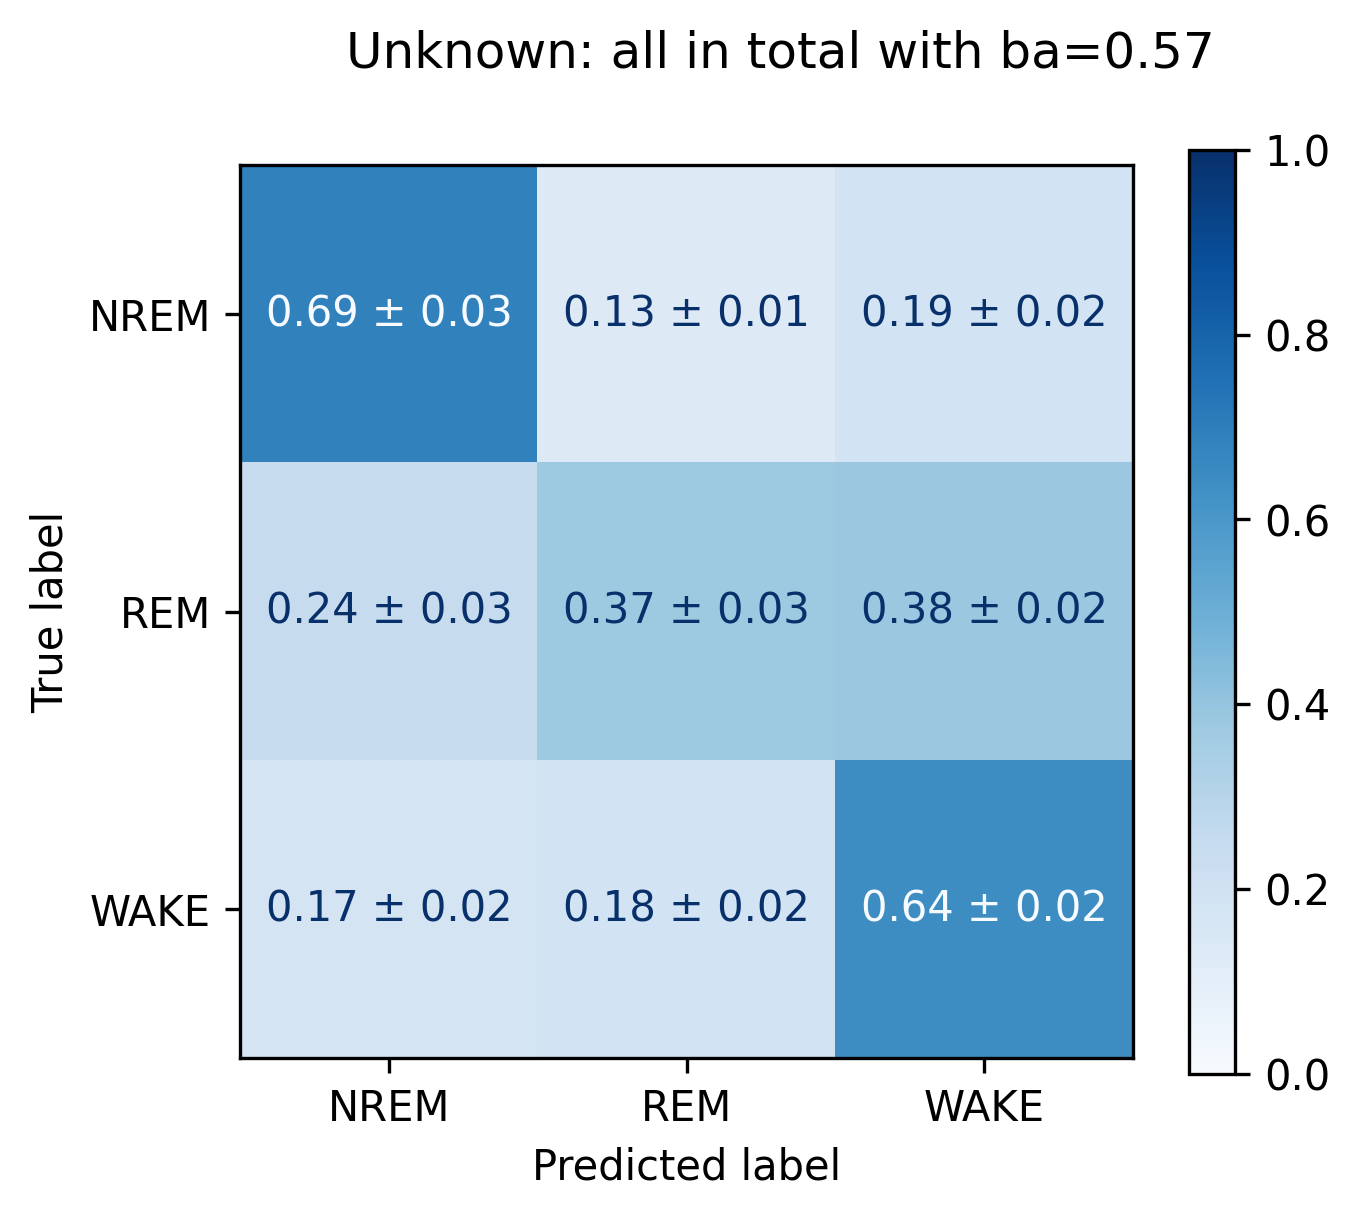

In [18]:
get_mean_cms_visual(by_animal_cms, graphic_train, prev_group_by_anim=True,
                   subplot_kwargs={"figsize":(4.8,4), 'dpi':300}, addon_text=False,
                   alt_se=True)

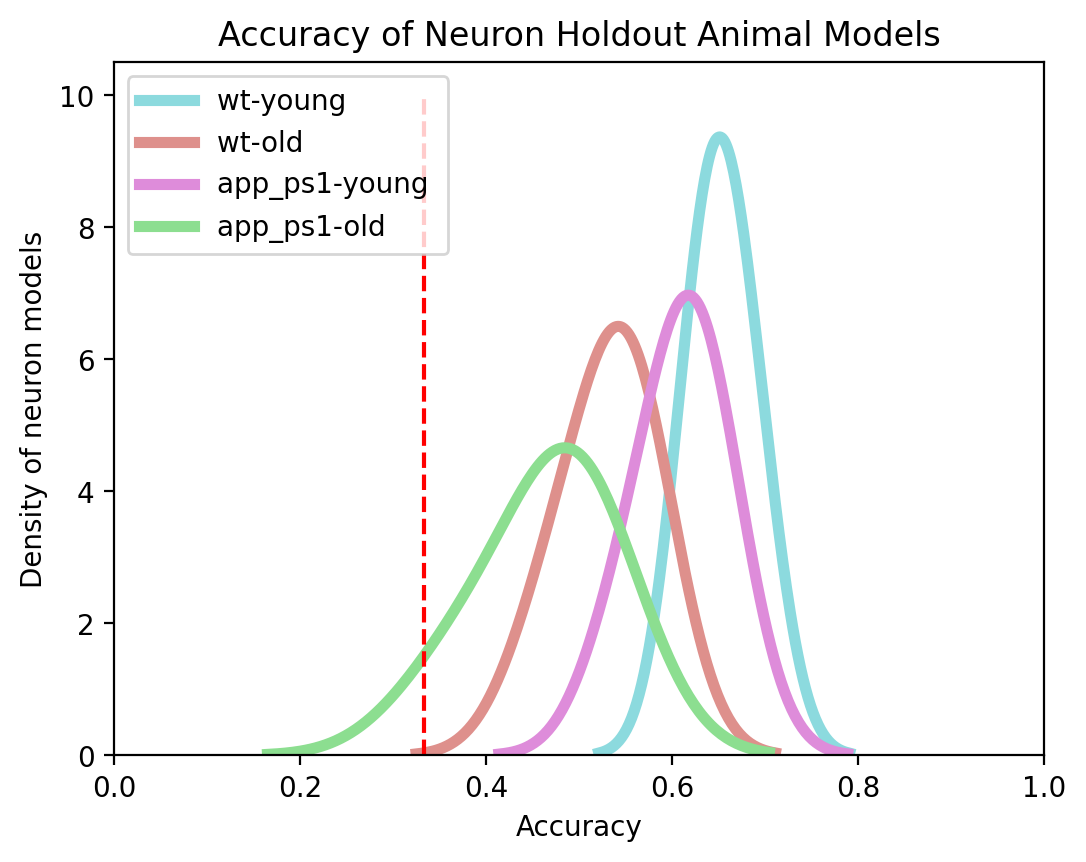

In [16]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(6,4.5))
get_cm_distrib_hist(by_animal_cms,graphic_train, "Accuracy of Neuron Holdout Animal Models",
                    by_geno=True, by_age=True, kde=True,
                        prev_group_by_anim=True,linewidth=4, bw_adjust=1.5)

In [25]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/by_animal/gtrain.pkl", "wb") as f:
        pickle.dump(graphic_train, f)

In [9]:
# models = mlp_by_cell(train, sampling_type='over')

In [40]:
#cms = get_cm(models, test, get_spiking=True, use_spike_matrix=False)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:00<00:00, 50037.31it/s]

Model failed: 'caf69(wt,old) in total' is not in list
Model failed: 'caf71(app_ps1,old) in total' is not in list
Model failed: 'caf73(app_ps1,old) in total' is not in list
Model failed: 'caf74(app_ps1,old) in total' is not in list
Model failed: 'caf75(app_ps1,old) in total' is not in list
Model failed: 'caf77(wt,old) in total' is not in list
Model failed: 'caf81(wt,old) in total' is not in list
Model failed: 'caf82(wt,old) in total' is not in list
Model failed: 'zbr106(wt,young) in total' is not in list
Model failed: 'zbr113(app_ps1,young) in total' is not in list
Model failed: 'zbr114(app_ps1,young) in total' is not in list
Model failed: 'zbr117(app_ps1,young) in total' is not in list
Model failed: 'zbr118(app_ps1,young) in total' is not in list
Model failed: 'zbr119(app_ps1,young) in total' is not in list
Model failed: 'bth90(wt,young) in total' is not in list
Model failed: 'bth95(wt,young) in total' is not in list
Model failed: 'bth100(wt,young) in total' is not in list


In [12]:
cms = load_safe()
i = 0
print(f"Loaded {len(cms)} confusion matrices from storage")
for cell in tqdm(train.cell.unique()):
    if cell not in cms:
        i+=1
        #before = time.time()
        item = mlp_individual(cell, train)
        if not len(item):
            print("SMOTE must have failed, just do oversampling instead, proceed")
            item = mlp_individual(cell, train, sampling_type='over')
            if not len(item):
                print("Skip this chump")
                continue
        #after = time.time()
        #print(f"This model took |{after-before} to train, had {item['training_length']} to go through")
        if item['model'].interrupted:
            print("Oh training got interrupted, exit!!!")
            save_safe(cms)
            break
        cm = get_individual_cm(item, test, get_spiking=True, use_spike_matrix=False)
        if not len(cm):
            print("This cm still failed somehow, bypassing")
            continue
        cms[cell] = cm[cell]
        if not i%5:
            #print("saving")
            save_safe(cms)

Successfully loaded the main cm dictionary
Loaded 3645 confusion matrices from storage


  0%|                                                                                                                                            | 0/4317 [00:00<?, ?it/s]

Hey this is tragic, this neuron doesn't have all three states, won't work :(
SMOTE must have failed, just do oversampling instead, proceed
Hey this is tragic, this neuron doesn't have all three states, won't work :(
Skip this chump
Hey this is tragic, this neuron doesn't have all three states, won't work :(
SMOTE must have failed, just do oversampling instead, proceed
Hey this is tragic, this neuron doesn't have all three states, won't work :(
Skip this chump


/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 84%|████████████████████████████████████████████████████████████████████████████████████████████████████████████                    | 3645/4317 [00:13<00:02, 261.90it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 84%|█████████████████████

 86%|████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                  | 3694/4317 [09:21<1:33:53,  9.04s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 86%|████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                  | 3695/4317 [09:22<1:09:20,  6.69s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 86%|████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                  | 3696/4317 [09:29<1:11:07,  6.87s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Sto

...

 95%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏     | 4119/4317 [1:02:01<30:22,  9.20s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 95%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏     | 4120/4317 [1:02:18<37:52, 11.54s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 95%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏     | 4121/4317 [1:02:35<42:42, 13.07s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Sto

 97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉    | 4177/4317 [1:14:12<12:27,  5.34s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉    | 4178/4317 [1:14:16<11:56,  5.15s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉    | 4179/4317 [1:14:19<10:01,  4.36s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Sto

sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 1, n_samples = 1
SMOTE must have failed, just do oversampling instead, proceed


 97%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌   | 4202/4317 [1:18:31<27:42, 14.46s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 97%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋   | 4203/4317 [1:18:32<19:36, 10.32s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 97%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋   | 4205/4317 [1:18:36<11:24,  6.11s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Sto

 99%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌ | 4268/4317 [1:30:43<22:24, 27.44s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 99%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌ | 4269/4317 [1:30:45<15:47, 19.74s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 99%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋ | 4271/4317 [1:30:50<08:28, 11.06s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Sto

In [ ]:
#print([(cm, cms[cm][0]) for cm in cms.keys()])

In [13]:
graphic_train = get_extended_condensed_data(train)

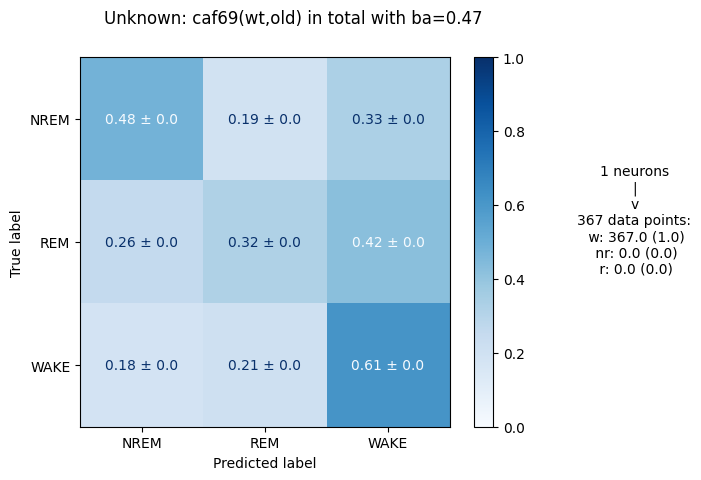

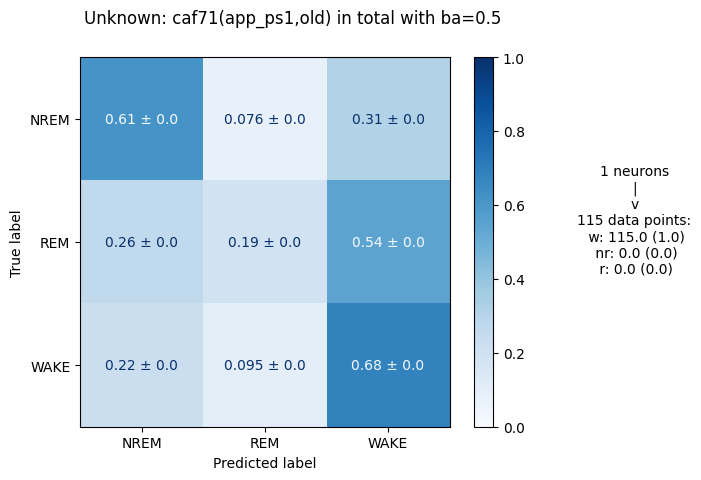

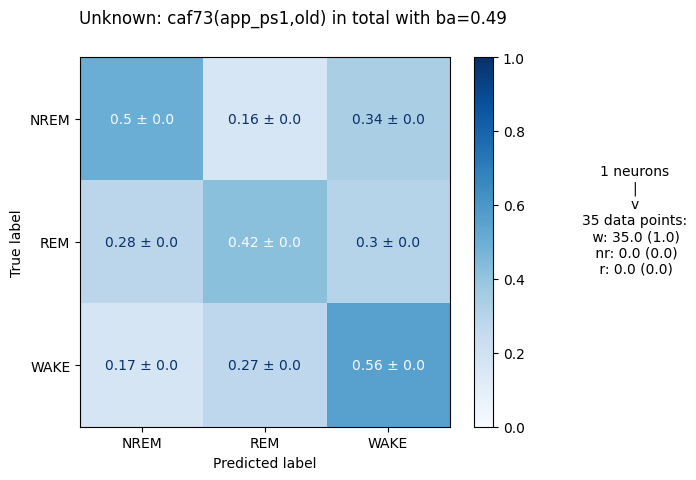

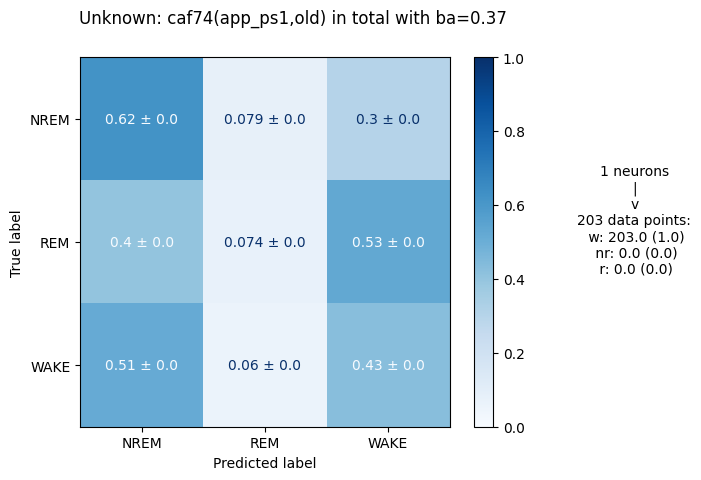

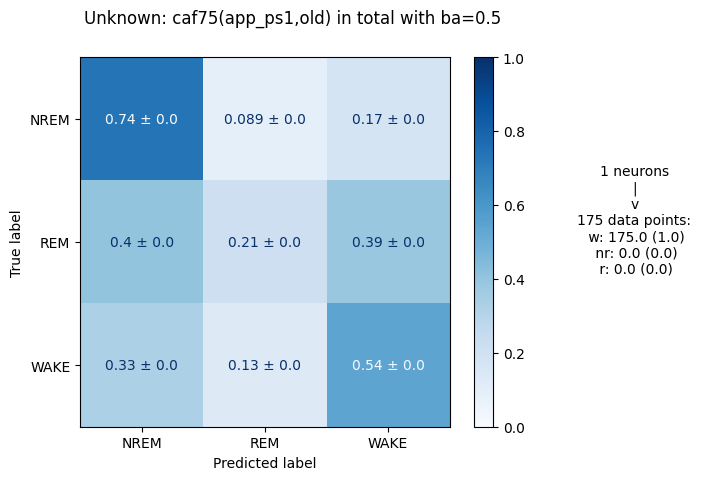

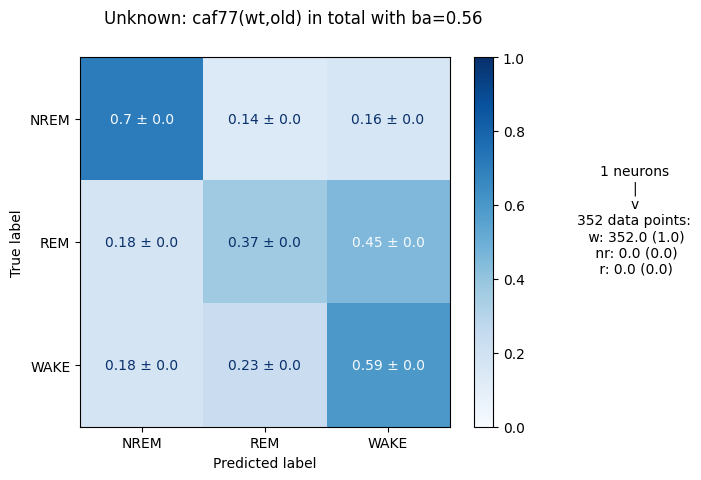

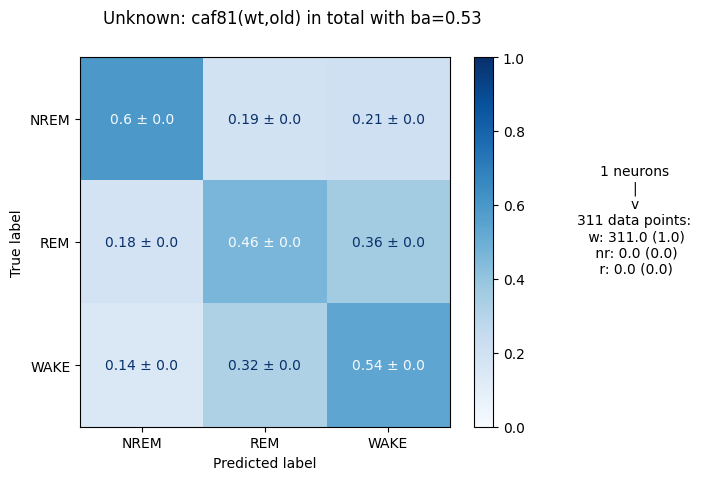

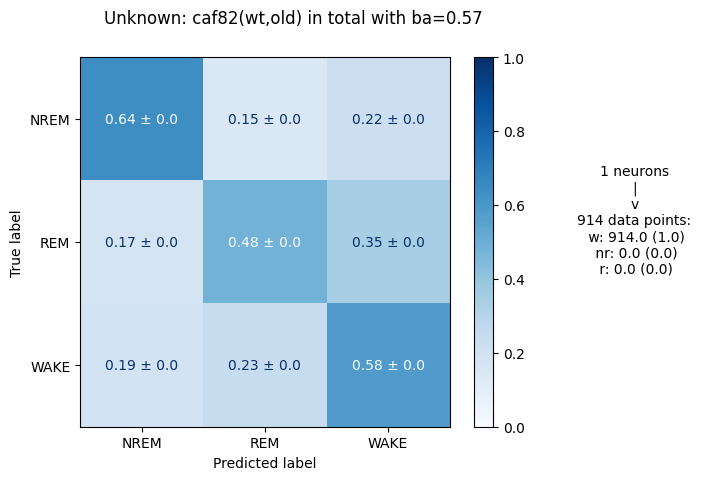

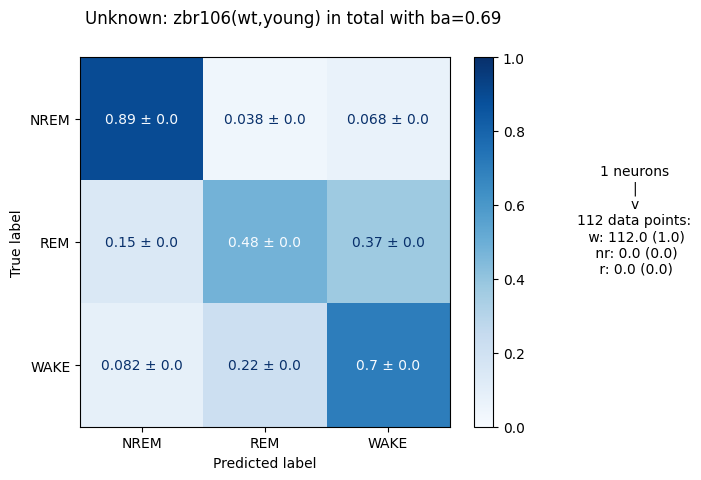

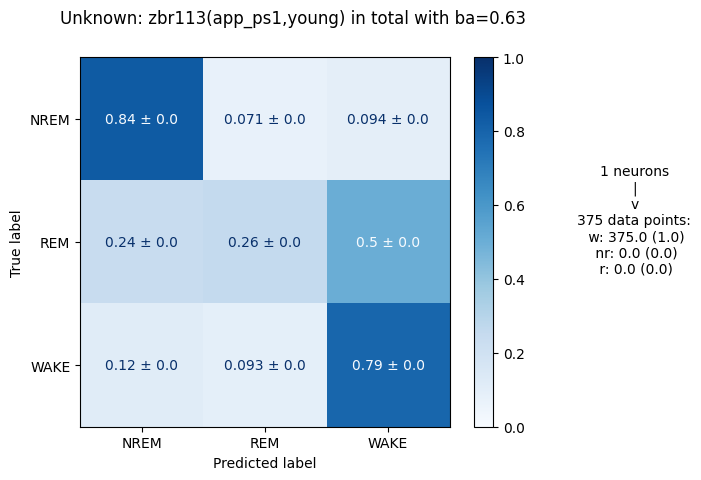

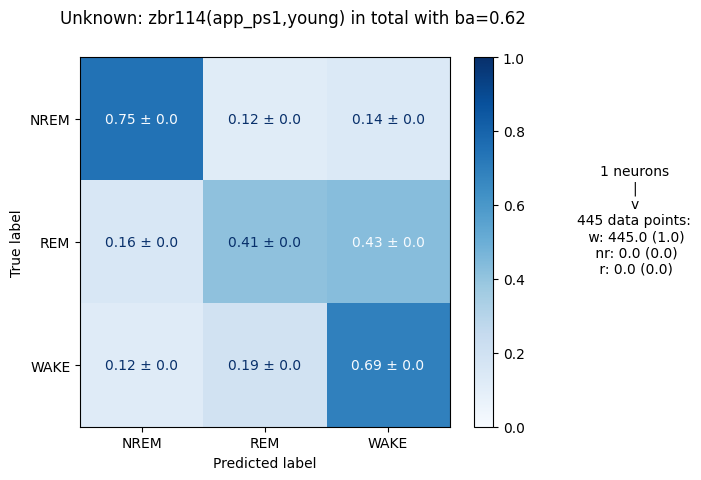

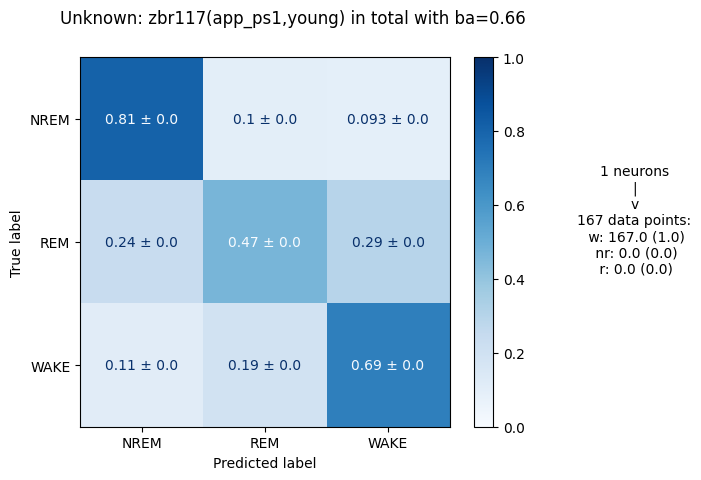

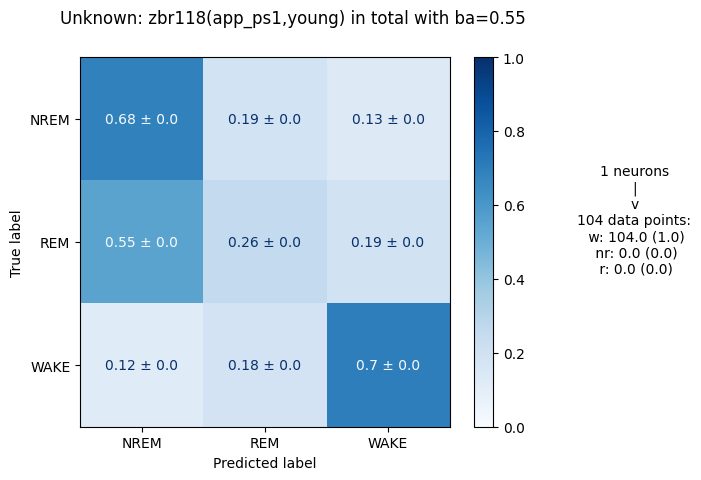

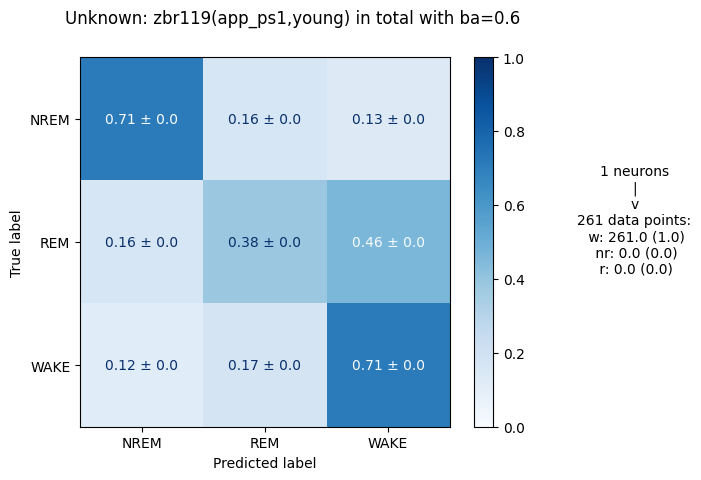

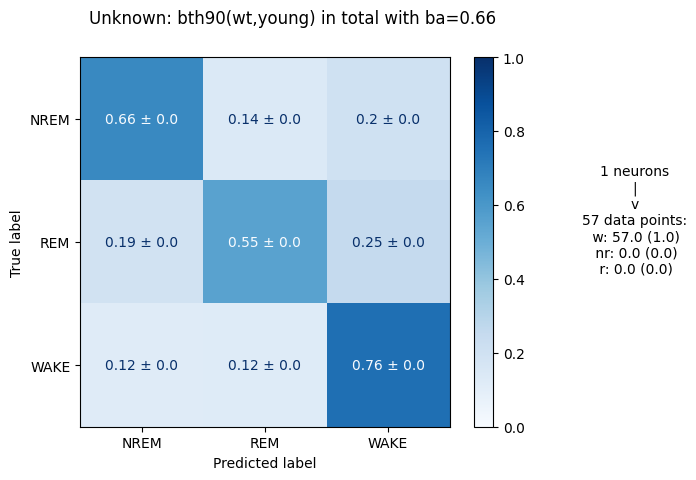

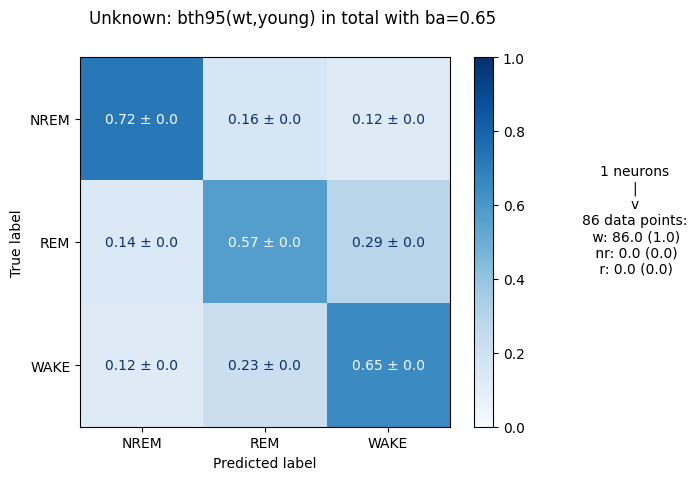

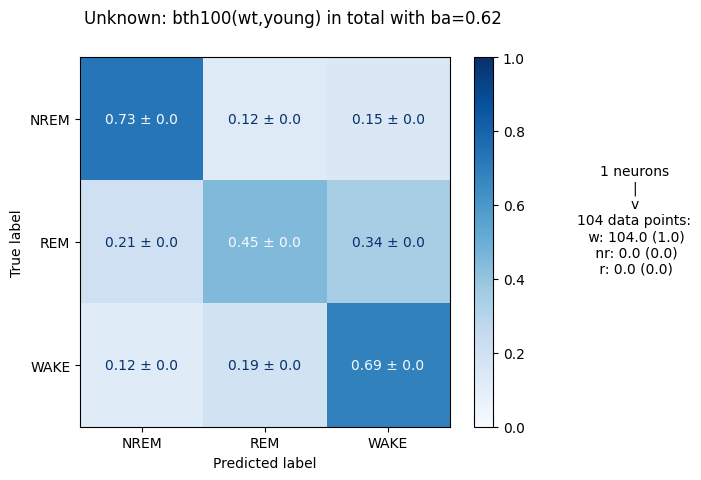

In [43]:
get_mean_cms_visual(cms, graphic_train, alt_se=True, by_animal=True)

In [5]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/by_animal/cms.pkl", "rb") as f:
            by_animal_cms = pickle.load(f)

In [6]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/full_individual_cell/baseline.pkl", "rb") as f:
            by_cell_cms = pickle.load(f)

In [61]:
graphic_train = get_extended_condensed_data(train)

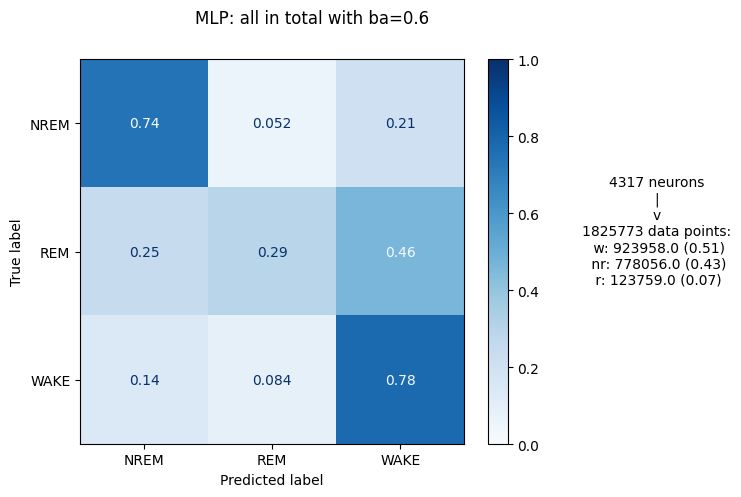

In [62]:
get_mean_cms_visual(by_cell_cms, graphic_train, "MLP", addon_text=True, subplot_kwargs={'figsize':(6.2, 5)}, 
                    addon_suff='pres', parent_file_p='', savefig=True)

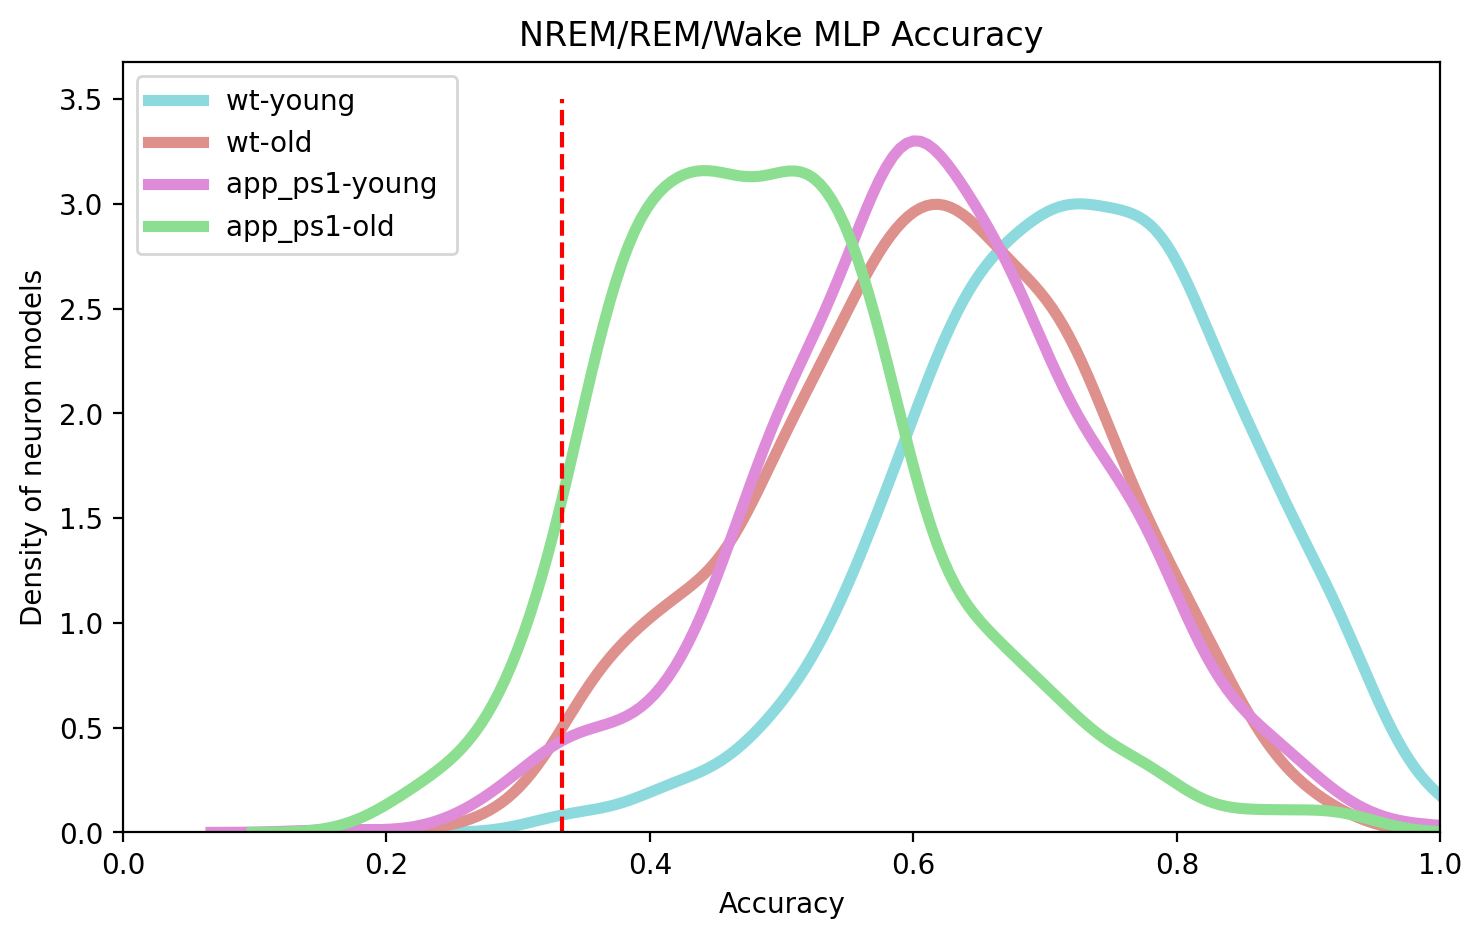

In [65]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(8.5,5))
get_cm_distrib_hist(by_cell_cms, graphic_train, "NREM/REM/Wake MLP Accuracy",plot_eval=[accuracy], kde=True, 
                    linewidth=4, by_geno=True, by_age=True)